# A2.3 Modelos de ensamble, SVM y redes neuronales — 611380

Secciones: 1) Preparación del escenario experimental, 2) Construcción de modelos, 3) Evaluación y comparación de desempeño, 4) Análisis crítico y conclusiones.

Objetivo: entrenar y comparar RF + Boosting + SVM + red neuronal sencilla desde cero sobre el mismo conjunto de clasificación analizado previamente (tres grupos de edad materna), reflexionando sobre capacidad predictiva, estabilidad y complejidad. El lector debe entender metodología-resultados-conclusiones sin leer el código.

Metodología: mismo `nacim24` ya depurado, partición 80/20 estratificada `random_state=10` (comparación justa), anti-leakage y métricas estándar (matriz de confusión, accuracy, sensibilidad, especificidad, precisión, F1).

## 1. Preparación del escenario experimental

### 1.1 Origen de datos y limpieza 

Fuente: INEGI Estadística de Nacimientos 2024 (`nacim24.dbf`, 44 vars). Justificación dominio: corte de adolescencia de 10 a 19 años (OMS, 2024). La depuración ya fue validada en análisis previos, por lo que aquí solo se reproduce en forma abreviada.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from dbfread import DBF

np.random.seed(10)

table = DBF('../a2/nacim24.dbf', encoding='latin1')
cols = ['ENT_REGIS', 'MUN_REGIS', 'LOC_REGIS', 'TLOC_REGIS', 'ENT_RESID', 'MUN_RESID', 'LOC_RESID', 'TLOC_RESID', 'ENT_OCURR', 'MUN_OCURR', 'LOC_OCURR', 'TLOC_OCURR', 'SEXO', 'EDAD_REG', 'EDAD_MADN', 'EDAD_PADN', 'DIA_NAC', 'MES_NAC', 'ANO_NAC', 'DIA_REG', 'MES_REG', 'ANO_REG', 'EDAD_MADR', 'EDAD_PADR', 'TIPO_NAC', 'ORDEN_PART', 'LUGAR_PART', 'Q_ATENDIO', 'HIJOS_VIVO', 'HIJOS_SOBR', 'EDOCIV_MAD', 'ESCOL_MAD', 'ESCOL_PAD', 'ACT_MAD', 'ACT_PAD', 'POS_MAD', 'POS_PAD', 'SITLAB_MAD', 'SITLAB_PAD', 'FUE_PRESE', 'HORA_NAC', 'MINUTO_NAC', 'COMPARECIO', 'DIS_RE_OAX']
data = pd.DataFrame([[rec[c] for c in cols] for rec in table], columns=cols)
print('Crudo:', data.shape)
print('Huecos disfrazados 99/9:')
print(' EDAD_MADN==99:', (data.EDAD_MADN == 99).sum())
print(' ESCOL_MAD==9:', (data.ESCOL_MAD == 9).sum())
print(' EDOCIV_MAD==9:', (data.EDOCIV_MAD == 9).sum())
print(' ACT_MAD==9:', (data.ACT_MAD == 9).sum())
print(' TLOC_RESID==99:', (data.TLOC_RESID == 99).sum())

clean = data[(data.EDAD_MADN != 99) & (data.ESCOL_MAD != 9) &
             (data.EDOCIV_MAD != 9) & (data.ACT_MAD != 9) &
             (data.TLOC_RESID != 99)].copy()
clean = clean.drop(columns=['HIJOS_VIVO'])  # corr 0.96 con ORDEN_PART
clean['ACT_MAD'] = clean['ACT_MAD'].map({1: 1, 2: 0})
clean = pd.get_dummies(clean, columns=['EDOCIV_MAD'], prefix='edociv', drop_first=True)
clean = pd.get_dummies(clean, columns=['ENT_RESID'], prefix='ent', drop_first=True)

def clasif(edad):
    if edad <= 19:
        return 'Adolescente'
    elif edad <= 34:
        return 'Adulta joven'
    else:
        return 'Adulta mayor'

clean['grupo_edad'] = clean.EDAD_MADN.apply(clasif)
print('Limpio:', clean.shape)

Crudo: (1672227, 44)
Huecos disfrazados 99/9:
 EDAD_MADN==99: 195421
 ESCOL_MAD==9: 212649
 EDOCIV_MAD==9: 210019
 ACT_MAD==9: 177259
 TLOC_RESID==99: 207022
Limpio: (1196565, 78)


**Diccionario de variables .** Las 4 variables numéricas son:
- `ESCOL_MAD`: años de escuela de la madre (a más valor, más estudios).
- `ORDEN_PART`: qué número de hijo es este parto (1 = su primer bebé, 5 = su quinto).
- `ACT_MAD`: si la madre trabaja (1) o no (0).
- `TLOC_RESID`: tamaño de la localidad donde vive (de rural a ciudad grande).

Además hay variables de *estado civil* (`edociv_*`: casada, soltera, unión libre, etc.) y de *estado de residencia* (`ent_*`: en qué estado del país vive). Estas últimas son de tipo sí/no, una por categoría.

### 1.2 Balance de clases y partición (misma para los 4 modelos)

Split `train_test_split(test_size=0.20, stratify=grupo_edad, random_state=10)` — la misma utilizada en los análisis previos para que la comparación sea justa. 

Tabla 1.1 — Distribución de grupo_edad (n total)
              Observaciones      %
Clase                             
Adulta joven         872478  72.92
Adolescente          168065  14.05
Adulta mayor         156022  13.04

Train: (957252, 78) | Test: (239313, 78)

Balance en train (%):
grupo_edad
Adulta joven    72.92
Adolescente     14.05
Adulta mayor    13.04
Name: proportion, dtype: float64

Balance en test (%):
grupo_edad
Adulta joven    72.92
Adolescente     14.05
Adulta mayor    13.04
Name: proportion, dtype: float64


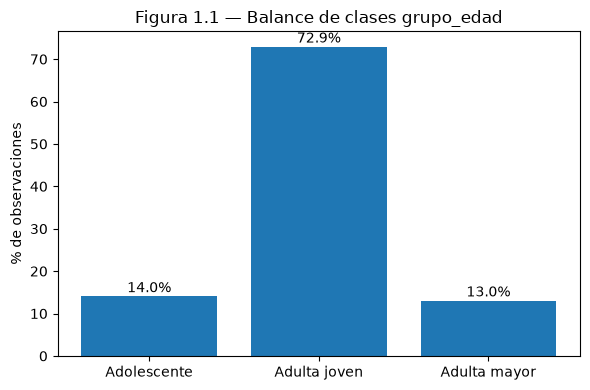

In [11]:
tabla_1_1 = clean.grupo_edad.value_counts().to_frame('Observaciones')
tabla_1_1['%'] = (clean.grupo_edad.value_counts(normalize=True) * 100).round(2)
tabla_1_1.index.name = 'Clase'
print('Tabla 1.1 — Distribución de grupo_edad (n total)')
print(tabla_1_1)

train, test = train_test_split(clean, test_size=0.2, stratify=clean['grupo_edad'], random_state=10)
print('\nTrain:', train.shape, '| Test:', test.shape)
print('\nBalance en train (%):')
print((train.grupo_edad.value_counts(normalize=True) * 100).round(2))
print('\nBalance en test (%):')
print((test.grupo_edad.value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
orden = ['Adolescente', 'Adulta joven', 'Adulta mayor']
vals = [ (clean.grupo_edad == c).mean() * 100 for c in orden ]
plt.bar(orden, vals)
plt.ylabel('% de observaciones')
plt.title('Figura 1.1 — Balance de clases grupo_edad')
for i, v in enumerate(vals):
    plt.text(i, v + 1, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()

De cada 100 nacimientos, unos 73 son de adultas jóvenes (20–34), 14 de adolescentes (10–19) y 13 de adultas mayores (35+). El grupo mayoritario es tan grande que un modelo flojo acertaría 73% con solo predecir siempre "adulta joven"; por eso aquí importan más las métricas por grupo (sensibilidad) que el acierto total. La partición conserva estos porcentajes en train y test, así que la comparación entre modelos es justa.

### 1.3 Confirmación de aptitud del dataset para RF / Boosting / SVM / NN

- **Escala.** Los árboles (RF, Boosting) comparan cada variable por separado, así que no necesitan ajustes. El SVM y la red mezclan todas las variables en sus cuentas: si una va de 0 a 30 y otra de 0 a 1, la primera gritaría más fuerte. Por eso se *estandarizan* (se ponen en la misma escala), ajustando solo con train para no espiar el test.
- **Supuestos.** Los árboles no suponen ninguna forma de los datos (aceptan los sí/no tal cual). El SVM tampoco supone forma, pero es sensible a la escala y a sus controles `C`/`γ`. La red no supone forma, pero es una caja negra: exige escala, validación y freno automático. El discriminante lineal de referencia exigía datos con forma de campana, cosa que estas variables discretas no cumplen; por eso se espera que los enfoques flexibles rindan más.
- **Tamaño y costo .** El train tiene ~950 mil filas × 40 columnas. RF y Boosting sí pueden con todo. El SVM crece en costo al cuadrado o al cubo: con todo tardaría horas, así que usa una muestra representativa de **40 mil** para entrenar (y otra de **30 mil** del test para evaluarlo). La red usa **100 mil** y aprende por grupitos (minibatches). Ambas muestras conservan el balance original y usan semilla fija, así que cualquiera puede repetirlas.
- **Variables.** 4 numéricas + dummies de estado civil y estado de residencia (≈40 columnas), idénticas a las del árbol de decisión de referencia.

In [12]:
cols_num = ['ESCOL_MAD', 'ACT_MAD', 'ORDEN_PART', 'TLOC_RESID']
cols_dummy = [c for c in clean.columns if c.startswith('edociv_') or c.startswith('ent_')]
feature_cols = cols_num + cols_dummy
print('Tabla 1.2 — Variables del modelo:', len(feature_cols))
print(' Num:', cols_num)
print(' Dummies:', len(cols_dummy))

X_train = train[feature_cols].astype(float).values
y_train = train['grupo_edad'].values
X_test = test[feature_cols].astype(float).values
y_test = test['grupo_edad'].values
print('\nX_train:', X_train.shape, '| X_test:', X_test.shape)
print('Clases:', np.unique(y_train))
print('Nulos en X_train:', np.isnan(X_train).sum(), '| Nulos en X_test:', np.isnan(X_test).sum())

# Submuestras por costo (el muestreo definitivo se fija en la sección 2, misma semilla)
from collections import Counter
rng = np.random.RandomState(10)
for n, nombre in [(40000, 'SVM-train'), (100000, 'NN-train')]:
    idx = rng.choice(len(X_train), n, replace=False)
    print(f'{nombre} n={n} balance %:', {k: round(v / n * 100, 2) for k, v in Counter(y_train[idx]).items()})
print('\nEscenario experimental verificado: partición y variables listas.')

Tabla 1.2 — Variables del modelo: 40
 Num: ['ESCOL_MAD', 'ACT_MAD', 'ORDEN_PART', 'TLOC_RESID']
 Dummies: 36

X_train: (957252, 40) | X_test: (239313, 40)
Clases: ['Adolescente' 'Adulta joven' 'Adulta mayor']
Nulos en X_train: 0 | Nulos en X_test: 0
SVM-train n=40000 balance %: {'Adulta joven': 72.98, 'Adulta mayor': 12.93, 'Adolescente': 14.09}
NN-train n=100000 balance %: {'Adolescente': 14.13, 'Adulta joven': 72.85, 'Adulta mayor': 13.02}

Escenario experimental verificado: partición y variables listas.


# 2. Construcción de modelos 

Supuestos e hiperparámetros :
- **RF**: en vez de un solo árbol (que cambia mucho con pocos datos), se entrenan 200 árboles y votan: eso estabiliza la predicción. Cada árbol puede encadenar hasta 12 preguntas y cada hoja final agrupa al menos 1000 madres (con casi un millón de datos se puede exigir eso). Cada árbol mira una muestra distinta de madres y de variables para que no piensen igual. A los grupos pequeños se les da más peso para que el voto no los aplaste. No hace falta estandarizar porque cada pregunta usa una sola variable.
- **Boosting** (`HistGradientBoosting`): en vez de votar en paralelo, cada árbol nuevo corrige los errores del anterior, aprendiendo despacio (tasa 0.07) con árboles chicos (profundidad 5). Se aparta 10% del train para vigilar: si 10 rondas seguidas no mejoran, se frena solo. También con peso extra a los grupos pequeños.
- **SVM**: busca la frontera que deja el mayor margen entre grupos. Como con un millón de filas tardaría horas, entrena con una muestra representativa de 40 mil (mismo balance) y se evalúa en 30 mil del test. Configuración estándar: frontera flexible (RBF), tolerancia media (C=1.0), un clasificador por cada par de grupos con voto entre los 3.
- **NN numpy**: red chica de 40 entradas → 64 → 32 → 3 salidas (una por grupo). Las capas intermedias usan ReLU (dejan pasar solo lo positivo, aprenden mejor) y la salida reparte probabilidades entre los 3 grupos. Aprende por grupitos de 512 con el método Adam (paso 0.001), máximo 30 vueltas, frenando si la validación deja de mejorar 3 vueltas seguidas. Con ~5 mil parámetros es viable para datos tabulares.
- **Keras ref**: misma receta (Adam 0.001, pérdida para 3 clases, grupitos de 32, freno a las 10 vueltas sin mejora). Si no está instalado, se omite sin romper nada.

In [13]:
import time
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score

clases = np.array(['Adolescente', 'Adulta joven', 'Adulta mayor'])
yid_train = np.searchsorted(clases, y_train)
yid_test = np.searchsorted(clases, y_test)
print('Mapeo clases→id:', dict(zip(clases, range(3))))
print('X_train:', X_train.shape, '| X_test:', X_test.shape)

Mapeo clases→id: {np.str_('Adolescente'): 0, np.str_('Adulta joven'): 1, np.str_('Adulta mayor'): 2}
X_train: (957252, 40) | X_test: (239313, 40)


### 2.1 Random Forest (train completo, n=957 252)

Se entrena en train completo: bagging + `m≈sqrt(p)` ya maneja n grande y el desbalance vía `balanced_subsample`. El `sanity check` en 20k de train es solo para confirmar que aprendió (la evaluación comparativa se presenta en la sección 3, con test).

RF entrenado en 0.3 min | árboles: 200
Tabla 2.1 — Top-10 importancias RF
ORDEN_PART    0.5639
ESCOL_MAD     0.1842
edociv_2      0.1147
ACT_MAD       0.0669
edociv_3      0.0373
TLOC_RESID    0.0123
ent_09        0.0078
ent_07        0.0040
ent_15        0.0011
ent_05        0.0009
dtype: float64
Sanity train-20k acc: 0.5041


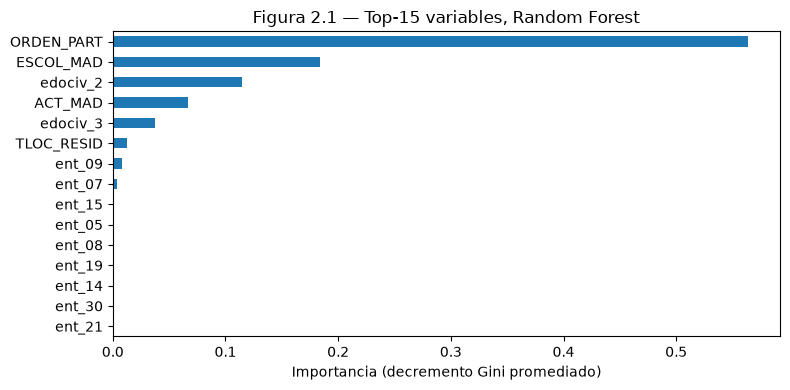

In [14]:
t0 = time.time()
rf = RandomForestClassifier(n_estimators=200, max_depth=12, min_samples_leaf=1000,
                            max_features='sqrt', class_weight='balanced_subsample',
                            n_jobs=-1, random_state=10)
rf.fit(X_train, y_train)
t_rf = time.time() - t0
print(f'RF entrenado en {t_rf/60:.1f} min | árboles: {len(rf.estimators_)}')

imp_rf = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print('Tabla 2.1 — Top-10 importancias RF')
print(imp_rf.head(10).round(4))

rng = np.random.RandomState(10)
s = rng.choice(len(X_train), 20000, replace=False)
print('Sanity train-20k acc:', round(accuracy_score(y_train[s], rf.predict(X_train[s])), 4))

plt.figure(figsize=(8, 4))
imp_rf.head(15)[::-1].plot.barh()
plt.xlabel('Importancia (decremento Gini promediado)')
plt.title('Figura 2.1 — Top-15 variables, Random Forest')
plt.tight_layout()
plt.show()

La Figura 2.1 muestra qué pesa en el voto del bosque. El orden del parto concentra más de la mitad de la decisión (0.56): tiene lógica, porque una madre con 5 o más partos casi nunca es adolescente, y una primeriza joven rara vez es adulta mayor. Le siguen la escolaridad (0.18) y estar casada (0.11): a menor escuela y sin matrimonio formal, más probable el grupo adolescente. El resto (trabajo, localidad, estados) aporta poco una vez sabido lo anterior.

### 2.2 Boosting 

Aprendizaje en cadena: cada árbol nuevo se concentra en lo que los anteriores clasificaron mal, avanzando despacio para no pasarse. El freno automático con 10% de validación interna evita que tantas iteraciones memoricen en vez de aprender.

Boosting entrenado en 0.4 min | iteraciones usadas: 200 / 200
Tabla 2.2 — train_score_ final: -0.7341 | valid_score_ final: -0.7398
Sanity train-20k acc: 0.541


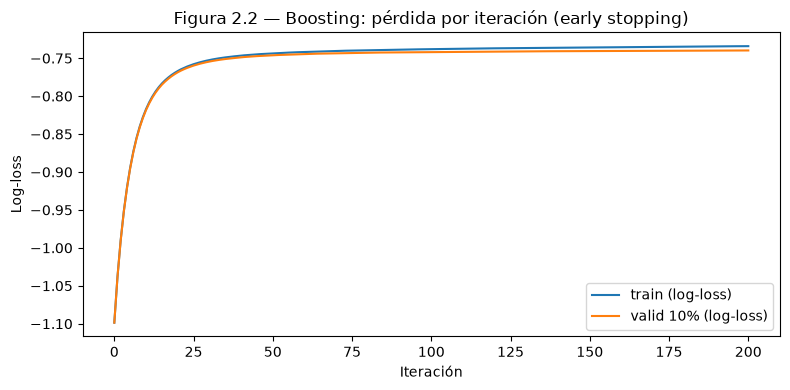

In [15]:
t0 = time.time()
gb = HistGradientBoostingClassifier(learning_rate=0.07, max_iter=200, max_depth=5,
                                    early_stopping=True, validation_fraction=0.1,
                                    n_iter_no_change=10, class_weight='balanced',
                                    random_state=10)
gb.fit(X_train, yid_train)
t_gb = time.time() - t0
print(f'Boosting entrenado en {t_gb/60:.1f} min | iteraciones usadas: {gb.n_iter_} / 200')
print(f'Tabla 2.2 — train_score_ final: {gb.train_score_[-1]:.4f} | valid_score_ final: {gb.validation_score_[-1]:.4f}')
print('Sanity train-20k acc:', round(accuracy_score(y_train[s], clases[gb.predict(X_train[s])]), 4))

plt.figure(figsize=(8, 4))
plt.plot(gb.train_score_, label='train (log-loss)')
plt.plot(gb.validation_score_, label='valid 10% (log-loss)')
plt.xlabel('Iteración')
plt.ylabel('Log-loss')
plt.title('Figura 2.2 — Boosting: pérdida por iteración (early stopping)')
plt.legend()
plt.tight_layout()
plt.show()

La Figura 2.2 muestra que la pérdida baja de forma pareja en train y validación y termina casi igual en ambas (0.734 contra 0.740): el modelo aprende sin memorizar. Usó las 200 iteraciones completas, señal de mejora continua hasta el final.

### 2.3 SVM 

Margen máximo con tolerancia a errores: la frontera se coloca lo más lejos posible de los tres grupos, permitiendo algunos casos cruzados para no volverse rígida. El sorteo simple con semilla conserva el balance verificado en la sección 1. La estandarización se ajusta solo en la submuestra de train.

In [16]:
from sklearn.model_selection import train_test_split as tts

rng = np.random.RandomState(10)
idx_svm = rng.choice(len(X_train), 40000, replace=False)
sc_svm = StandardScaler().fit(X_train[idx_svm])
Xs_tr = sc_svm.transform(X_train[idx_svm])
print('Balance SVM-train:', pd.Series(y_train[idx_svm]).value_counts(normalize=True).round(4).to_dict())

t0 = time.time()
svm = SVC(C=1.0, kernel='rbf', gamma='scale', class_weight='balanced',
          cache_size=1000, random_state=10)
svm.fit(Xs_tr, y_train[idx_svm])
t_svm = time.time() - t0
print(f'SVM entrenado en {t_svm/60:.1f} min')
print('Tabla 2.3 — kernel=rbf, C=1.0, gamma=scale, esquema OvO (3 clasificadores)')
print(' n_support_ por clase:', svm.n_support_, '| total SV:', svm.n_support_.sum())

_, X_test30, _, y_test30 = tts(X_test, y_test, test_size=30000, stratify=y_test, random_state=10)
print('SVM-test30:', X_test30.shape, pd.Series(y_test30).value_counts(normalize=True).round(4).to_dict())

Balance SVM-train: {'Adulta joven': 0.7298, 'Adolescente': 0.1409, 'Adulta mayor': 0.1293}
SVM entrenado en 0.6 min
Tabla 2.3 — kernel=rbf, C=1.0, gamma=scale, esquema OvO (3 clasificadores)
 n_support_ por clase: [ 2912 28840  3971] | total SV: 35723
SVM-test30: (30000, 40) {'Adulta joven': 0.7291, 'Adolescente': 0.1405, 'Adulta mayor': 0.1304}


### 2.4 Red neuronal 

La red transforma las 40 variables en dos niveles de 64 y 32 señales intermedias antes de repartir la probabilidad entre los 3 grupos. Los pesos arrancan con valores chicos aleatorios (semilla fija) y se ajustan por prueba y corrección: se mide el error, se calcula cuánto aportó cada conexión y se corrige en reversa, miles de veces por vuelta. La validación decide cuándo parar.

NN train/valid: (90000, 40) (10000, 40)
epoch  1 loss=0.9454 acc=0.6126 vloss=0.9341 vacc=0.6172
epoch  2 loss=0.8786 acc=0.6647 vloss=0.8681 vacc=0.6686
epoch  3 loss=0.8508 acc=0.6939 vloss=0.8411 vacc=0.6946
epoch  4 loss=0.8346 acc=0.7091 vloss=0.8255 vacc=0.7098
epoch  5 loss=0.8226 acc=0.7179 vloss=0.8142 vacc=0.7183
epoch  6 loss=0.8126 acc=0.7236 vloss=0.8049 vacc=0.7243
epoch  7 loss=0.8039 acc=0.7261 vloss=0.7968 vacc=0.7265
epoch  8 loss=0.7961 acc=0.7265 vloss=0.7896 vacc=0.7273
epoch  9 loss=0.7890 acc=0.7269 vloss=0.7830 vacc=0.7272
epoch 10 loss=0.7826 acc=0.7271 vloss=0.7770 vacc=0.7275
epoch 11 loss=0.7766 acc=0.7274 vloss=0.7715 vacc=0.7280
epoch 12 loss=0.7711 acc=0.7277 vloss=0.7664 vacc=0.7280
epoch 13 loss=0.7659 acc=0.7282 vloss=0.7617 vacc=0.7282
epoch 14 loss=0.7611 acc=0.7284 vloss=0.7573 vacc=0.7284
epoch 15 loss=0.7566 acc=0.7287 vloss=0.7532 vacc=0.7292
epoch 16 loss=0.7524 acc=0.7290 vloss=0.7494 vacc=0.7293
epoch 17 loss=0.7484 acc=0.7297 vloss=0.7457 vac

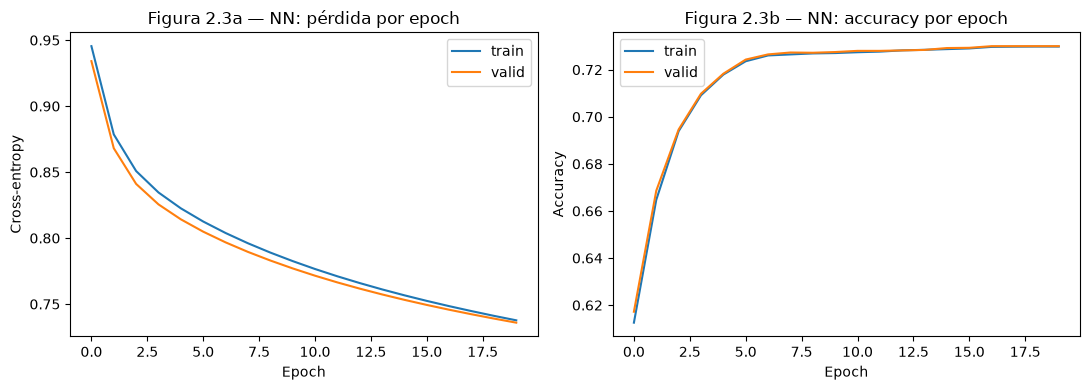

In [17]:
idx_nn = np.random.RandomState(10).choice(len(X_train), 100000, replace=False)
sc_nn = StandardScaler().fit(X_train[idx_nn])
Xn = sc_nn.transform(X_train[idx_nn]).astype(np.float64)
yn = yid_train[idx_nn]
Xtr, Xva, ytr, yva = tts(Xn, yn, test_size=0.1, stratify=yn, random_state=10)
print('NN train/valid:', Xtr.shape, Xva.shape)

def relu(z): return np.maximum(z, 0)
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)

r = np.random.RandomState(10)
W1 = r.randn(40, 64) * np.sqrt(2/40); b1 = np.zeros(64)
W2 = r.randn(64, 32) * np.sqrt(2/64); b2 = np.zeros(32)
W3 = r.randn(32, 3) * np.sqrt(2/32);  b3 = np.zeros(3)
Ps = [[np.zeros_like(W1), np.zeros_like(b1)], [np.zeros_like(W2), np.zeros_like(b2)], [np.zeros_like(W3), np.zeros_like(b3)]]

lr, l2, bs = 0.001, 1e-4, 512
b1a, b2a, eps, t = 0.9, 0.999, 1e-8, 0
Ytr = np.eye(3)[ytr]
hist = {'loss': [], 'acc': [], 'vloss': [], 'vacc': []}
best = (-1, None)
wait = 0
t0 = time.time()
for epoch in range(30):
    sh = np.random.RandomState(10 + epoch).permutation(len(Xtr))
    for i in range(0, len(Xtr), bs):
        t += 1
        xb = Xtr[sh[i:i+bs]]
        yb = Ytr[sh[i:i+bs]]
        m = len(xb)
        z1 = xb @ W1 + b1; a1 = relu(z1)
        z2 = a1 @ W2 + b2; a2 = relu(z2)
        z3 = a2 @ W3 + b3; p = softmax(z3)
        dz3 = (p - yb) / m
        dW3 = a2.T @ dz3 + l2 * W3; db3 = dz3.sum(axis=0)
        da2 = dz3 @ W3.T; dz2 = da2 * (z2 > 0)
        dW2 = a1.T @ dz2 + l2 * W2; db2 = dz2.sum(axis=0)
        da1 = dz2 @ W2.T; dz1 = da1 * (z1 > 0)
        dW1 = xb.T @ dz1 + l2 * W1; db1 = dz1.sum(axis=0)
        for (W, b, P, gW, gb_) in [(W1, b1, Ps[0], dW1, db1), (W2, b2, Ps[1], dW2, db2), (W3, b3, Ps[2], dW3, db3)]:
            P[0] = b1a * P[0] + (1 - b1a) * gW
            P[1] = b1a * P[1] + (1 - b1a) * gb_
            mW = P[0] / (1 - b1a**t); mb = P[1] / (1 - b1a**t)
            W -= lr * mW; b -= lr * mb
    def ev(X, y):
        p = softmax(relu(relu(X @ W1 + b1) @ W2 + b2) @ W3 + b3)
        return -(np.log(p[np.arange(len(y)), y] + 1e-12)).mean(), (p.argmax(1) == y).mean()
    l, a = ev(Xtr, ytr); vl, va = ev(Xva, yva)
    hist['loss'].append(l); hist['acc'].append(a); hist['vloss'].append(vl); hist['vacc'].append(va)
    print(f'epoch {epoch+1:2d} loss={l:.4f} acc={a:.4f} vloss={vl:.4f} vacc={va:.4f}')
    if va > best[0] + 1e-4:
        best = (va, (W1.copy(), b1.copy(), W2.copy(), b2.copy(), W3.copy(), b3.copy()))
        wait = 0
    else:
        wait += 1
        if wait >= 3:
            print(f'Early stop en epoch {epoch+1}')
            break
W1, b1, W2, b2, W3, b3 = best[1]
t_nn = time.time() - t0
print(f'Tabla 2.4 — NN numpy: epochs={len(hist["loss"])} tiempo={t_nn/60:.1f} min mejor vacc={best[0]:.4f}')

plt.figure(figsize=(11, 4))
plt.subplot(1, 2, 1)
plt.plot(hist['loss'], label='train'); plt.plot(hist['vloss'], label='valid')
plt.xlabel('Epoch'); plt.ylabel('Cross-entropy'); plt.legend()
plt.title('Figura 2.3a — NN: pérdida por epoch')
plt.subplot(1, 2, 2)
plt.plot(hist['acc'], label='train'); plt.plot(hist['vacc'], label='valid')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend()
plt.title('Figura 2.3b — NN: accuracy por epoch')
plt.tight_layout()
plt.show()

Las Figuras 2.3a y 2.3b muestran un aprendizaje sano en apariencia: la pérdida (2.3a) cae rápido al inicio y luego se aplana, mientras la exactitud (2.3b) sube y se estabiliza; la validación acompaña al train hasta que el freno detiene en la vuelta 20. El problema de la red no está en cómo entrena, sino en a quién atiende: al no darle peso extra a los grupos pequeños, aprende a acertar con la mayoría e ignora al resto, como se verá en la sección 3.

### 2.5 Referencia Keras (misma receta)

Si `tensorflow` está disponible se entrena `Dense(64,relu)→Dense(32,relu)→Dense(3,softmax)` con `Adam(0.001)`, `sparse_categorical_crossentropy`, batch 32 y `EarlyStopping(val_accuracy, patience=10, restore_best)`. En laptop CPU sin TF se omite sin romper el reporte.

Epoch 1/30


/Users/jgalvann/anaconda3/envs/profile_env/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


2813/2813 - 2s - 545us/step - accuracy: 0.7411 - loss: 0.6236 - val_accuracy: 0.7464 - val_loss: 0.5985
Epoch 2/30
2813/2813 - 1s - 340us/step - accuracy: 0.7461 - loss: 0.6014 - val_accuracy: 0.7490 - val_loss: 0.5957
Epoch 3/30
2813/2813 - 1s - 344us/step - accuracy: 0.7474 - loss: 0.5982 - val_accuracy: 0.7511 - val_loss: 0.5927
Epoch 4/30
2813/2813 - 1s - 346us/step - accuracy: 0.7485 - loss: 0.5961 - val_accuracy: 0.7518 - val_loss: 0.5935
Epoch 5/30
2813/2813 - 1s - 345us/step - accuracy: 0.7486 - loss: 0.5941 - val_accuracy: 0.7469 - val_loss: 0.5948
Epoch 6/30
2813/2813 - 1s - 348us/step - accuracy: 0.7490 - loss: 0.5938 - val_accuracy: 0.7538 - val_loss: 0.5900
Epoch 7/30
2813/2813 - 1s - 346us/step - accuracy: 0.7498 - loss: 0.5926 - val_accuracy: 0.7511 - val_loss: 0.5921
Epoch 8/30
2813/2813 - 1s - 346us/step - accuracy: 0.7498 - loss: 0.5918 - val_accuracy: 0.7511 - val_loss: 0.5951
Epoch 9/30
2813/2813 - 1s - 351us/step - accuracy: 0.7501 - loss: 0.5913 - val_accuracy: 0.

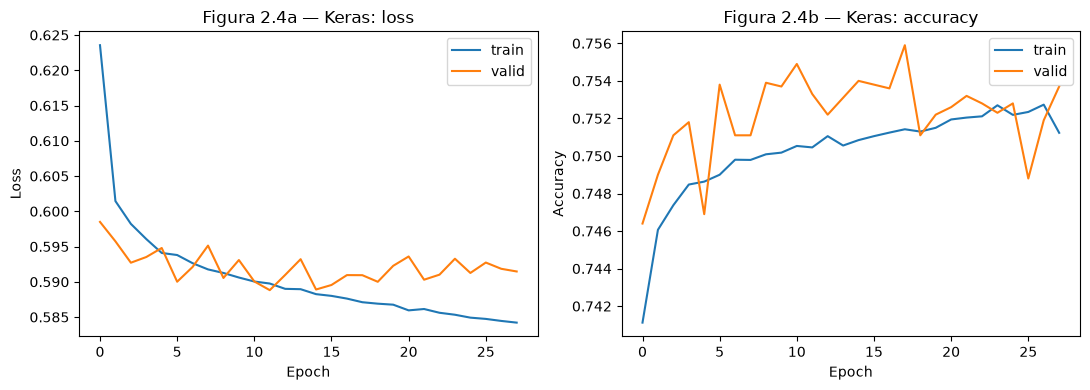

In [18]:
keras_ok = False
try:
    import tensorflow as tf
    from tensorflow import keras
    keras_ok = True
except ModuleNotFoundError:
    print('Nota Tabla 2.5 — tensorflow no instalado en este equipo; referencia Keras omitida (no afecta los 4 modelos exigidos).')

if keras_ok:
    t0 = time.time()
    model = keras.Sequential([keras.layers.Dense(64, activation='relu', input_shape=(40,)),
                              keras.layers.Dense(32, activation='relu'),
                              keras.layers.Dense(3, activation='softmax')])
    model.compile(optimizer=keras.optimizers.Adam(0.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    cb = keras.callbacks.EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True)
    h = model.fit(Xn, yn, batch_size=32, epochs=30, validation_split=0.1, callbacks=[cb], verbose=2)
    t_keras = time.time() - t0
    print(f'Keras ref: epochs={len(h.history["loss"])} tiempo={t_keras/60:.1f} min')
    plt.figure(figsize=(11, 4))
    plt.subplot(1, 2, 1); plt.plot(h.history['loss'], label='train'); plt.plot(h.history['val_loss'], label='valid')
    plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.title('Figura 2.4a — Keras: loss')
    plt.subplot(1, 2, 2); plt.plot(h.history['accuracy'], label='train'); plt.plot(h.history['val_accuracy'], label='valid')
    plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.title('Figura 2.4b — Keras: accuracy')
    plt.tight_layout(); plt.show()

In [23]:
print('Tabla 2.6 — Resumen de modelos construidos (todo entrenado solo con train)')
print(f' RF        : full train 957252 | 200 árboles d12 leaf1000 sqrt balanced_sub | {t_rf/60:.1f} min')
print(f' Boosting  : full train 957252 | lr0.07 iter{gb.n_iter_}/200 d5 earlystop balanced | {t_gb/60:.1f} min')
print(f' SVM RBF   : submuestra 40000  | C=1.0, gamma=scale, OvO + scaler | {t_svm/60:.1f} min | SV={svm.n_support_.sum()}')
print(f' NN numpy  : submuestra 100000 | 40-64-32-3 Adam0.001 bs512 epochs{len(hist["loss"])} | {t_nn/60:.1f} min')
print('Keras ref :', 'entrenada' if keras_ok else 'omitida (sin TF)')
print('Modelos construidos: RF, Boosting, SVM RBF y NN numpy Keras.')

Tabla 2.6 — Resumen de modelos construidos (todo entrenado solo con train)
 RF        : full train 957252 | 200 árboles d12 leaf1000 sqrt balanced_sub | 0.3 min
 Boosting  : full train 957252 | lr0.07 iter200/200 d5 earlystop balanced | 0.4 min
 SVM RBF   : submuestra 40000  | C=1.0, gamma=scale, OvO + scaler | 0.6 min | SV=35723
 NN numpy  : submuestra 100000 | 40-64-32-3 Adam0.001 bs512 epochs20 | 0.0 min
Keras ref : entrenada
Modelos construidos: RF, Boosting, SVM RBF y NN numpy Keras.


Exactitud del arbolito en train: 0.7375


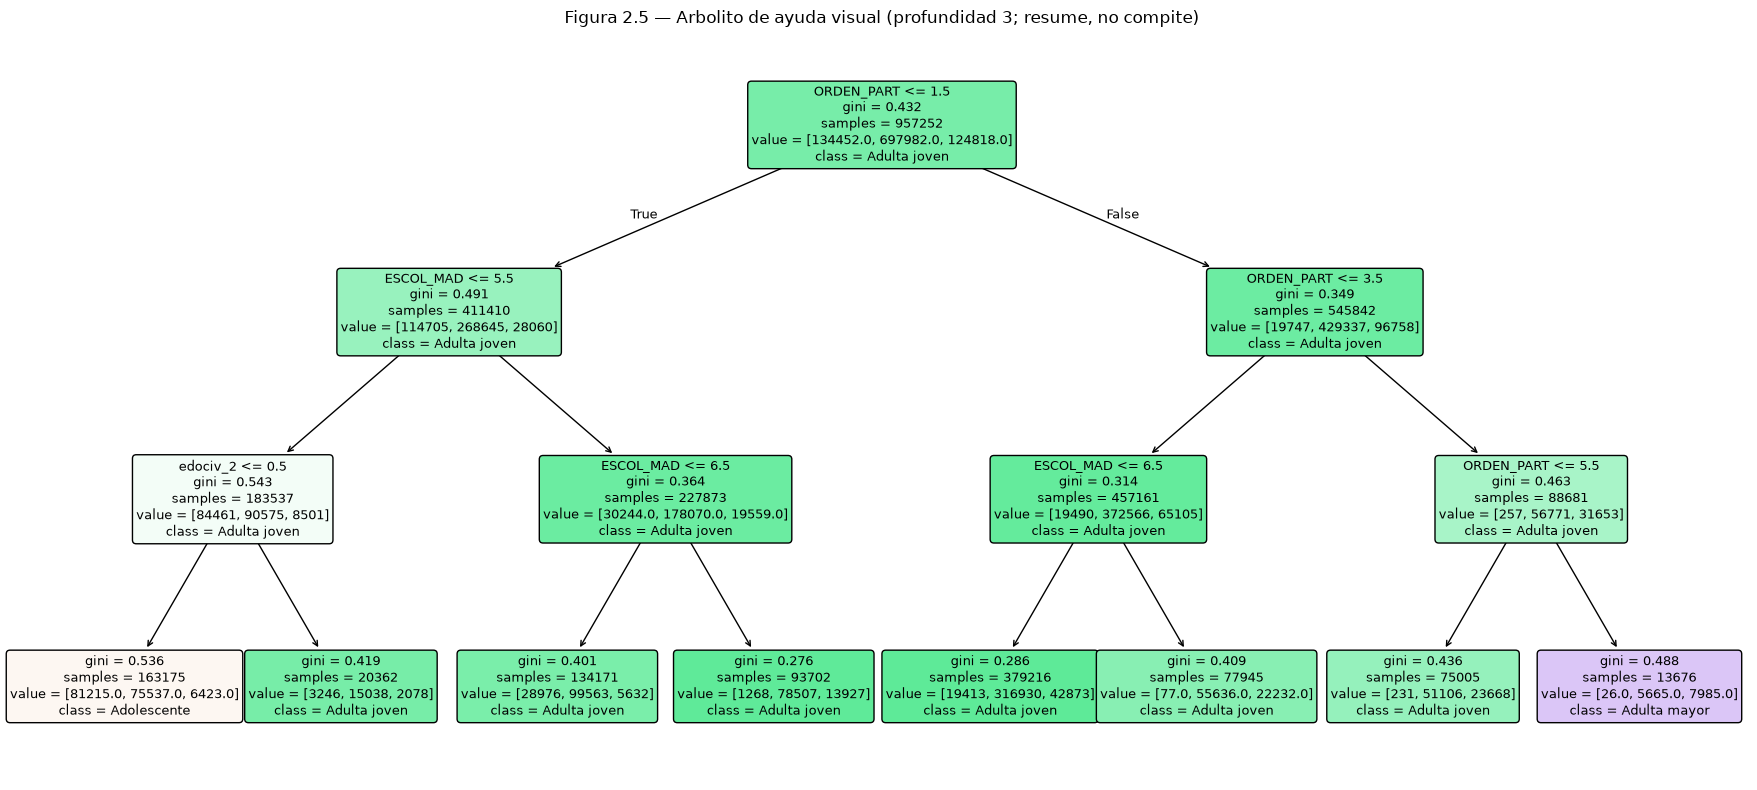

In [24]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

arbol_ayuda = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5000, random_state=10)
arbol_ayuda.fit(X_train, y_train)
print('Exactitud del arbolito en train:', round(accuracy_score(y_train, arbol_ayuda.predict(X_train)), 4))

plt.figure(figsize=(18, 8))
plot_tree(arbol_ayuda, feature_names=feature_cols,
          class_names=['Adolescente', 'Adulta joven', 'Adulta mayor'],
          filled=True, rounded=True, fontsize=9)
plt.title('Figura 2.5 — Arbolito de ayuda visual (profundidad 3; resume, no compite)')
plt.tight_layout()
plt.show()


La Figura 2.5 se lee de arriba hacia abajo: cada caja es una pregunta de sí/no y se sigue la rama correspondiente hasta llegar a una hoja, que dice el grupo y cuántas madres cayeron ahí. El color indica el grupo ganador y la intensidad qué tan pura quedó la hoja. Con solo 3 niveles resume lo que el bosque de 200 árboles hace en grande: el primer corte es el orden del parto (más de ~5 partos lleva directo a adulta mayor); por la otra rama, ser primeriza con poca escuela y sin matrimonio formal lleva a adolescente; el resto cae en adulta joven. Si tus umbrales difieren en decimales con lo impreso arriba, valen los de tu figura.

## 3. Evaluación y comparación de desempeño 

Cada modelo se evalúa una sola vez en test con la misma batería: accuracy, balanced accuracy, sensibilidad (recall), especificidad, precisión y F1 por clase, más matriz de confusión. RF, Boosting y la red se evalúan en el test completo (n=239 313); el SVM, por su costo predictivo, en el subconjunto test-30k fijado en la sección 2. Como referencia se incluyen los valores del discriminante lineal y del árbol único obtenidos previamente sobre la misma partición.

In [20]:
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, precision_recall_fscore_support)

def metricas(y_true, y_pred, nombre):
    cm = confusion_matrix(y_true, y_pred, labels=list(clases))
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=list(clases), zero_division=0)
    total = cm.sum()
    spec = []
    for i in range(len(clases)):
        tp = cm[i, i]
        fn = cm[i, :].sum() - tp
        fp = cm[:, i].sum() - tp
        tn = total - tp - fn - fp
        spec.append(tn / (tn + fp))
    return {'cm': cm, 'acc': accuracy_score(y_true, y_pred),
            'bacc': balanced_accuracy_score(y_true, y_pred),
            'sens': rec, 'spec': np.array(spec), 'prec': prec, 'f1': f1}

t0 = time.time(); pred_rf = rf.predict(X_test); t_pred_rf = time.time() - t0
print(f'RF predice test completo en {t_pred_rf/60:.1f} min')
t0 = time.time(); pred_gb = clases[gb.predict(X_test)]; t_pred_gb = time.time() - t0
print(f'Boosting predice test completo en {t_pred_gb/60:.1f} min')
t0 = time.time(); pred_svm = svm.predict(sc_svm.transform(X_test30)); t_pred_svm = time.time() - t0
print(f'SVM predice test-30k en {t_pred_svm/60:.1f} min')

Xt_all = sc_nn.transform(X_test)
p_all = softmax(relu(relu(Xt_all @ W1 + b1) @ W2 + b2) @ W3 + b3)
pred_nn = clases[p_all.argmax(axis=1)]
print('NN predice test completo.')

m_rf = metricas(y_test, pred_rf, 'RF')
m_gb = metricas(y_test, pred_gb, 'Boosting')
m_svm = metricas(y_test30, pred_svm, 'SVM')
m_nn = metricas(y_test, pred_nn, 'NN')
print('Métricas calculadas para los 4 modelos.')

RF predice test completo en 0.0 min
Boosting predice test completo en 0.0 min
SVM predice test-30k en 0.8 min
NN predice test completo.
Métricas calculadas para los 4 modelos.


In [21]:
filas = []
for nombre, m in [('RF', m_rf), ('Boosting', m_gb), ('SVM*', m_svm), ('NN numpy', m_nn)]:
    filas.append([nombre, m['acc'], m['bacc'],
                  m['sens'][0], m['sens'][1], m['sens'][2],
                  m['spec'][0], m['spec'][1], m['spec'][2],
                  m['prec'][0], m['prec'][1], m['prec'][2],
                  m['f1'][0], m['f1'][1], m['f1'][2]])
tabla_3_1 = pd.DataFrame(filas, columns=['Modelo', 'Accuracy', 'Balanced_ACC',
    'Sens_Adol', 'Sens_Joven', 'Sens_Mayor',
    'Spec_Adol', 'Spec_Joven', 'Spec_Mayor',
    'Prec_Adol', 'Prec_Joven', 'Prec_Mayor',
    'F1_Adol', 'F1_Joven', 'F1_Mayor']).round(4)
print('Tabla 3.1 — Desempeño en prueba (SVM* en test-30k; resto en test completo)')
print(tabla_3_1.to_string(index=False))

print('\nTabla 3.2 — Referencia: modelos previos, misma partición')
print(' Discriminante lineal: acc 0.724 / bacc 0.370 / Sens_Adol 0.04 (colapsa a la clase mayoritaria)')
print(' Árbol único podado  : acc 0.737 / bacc 0.518 / Sens_Adol 0.60 / Sens_Mayor 0.06')

Tabla 3.1 — Desempeño en prueba (SVM* en test-30k; resto en test completo)
  Modelo  Accuracy  Balanced_ACC  Sens_Adol  Sens_Joven  Sens_Mayor  Spec_Adol  Spec_Joven  Spec_Mayor  Prec_Adol  Prec_Joven  Prec_Mayor  F1_Adol  F1_Joven  F1_Mayor
      RF    0.5047        0.6425     0.8225      0.4093      0.6959     0.7884      0.8166      0.6967     0.3885      0.8573      0.2559   0.5277    0.5541    0.3742
Boosting    0.5419        0.6523     0.8385      0.4648      0.6537     0.7875      0.8029      0.7446     0.3921      0.8639      0.2774   0.5343    0.6044    0.3895
    SVM*    0.5381        0.6311     0.8261      0.4725      0.5946     0.7823      0.7670      0.7566     0.3827      0.8452      0.2681   0.5231    0.6062    0.3696
NN numpy    0.7288        0.3343     0.0021      0.9987      0.0022     0.9997      0.0024      0.9991     0.5547      0.7294      0.2604   0.0042    0.8430    0.0044

Tabla 3.2 — Referencia: modelos previos, misma partición
 Discriminante lineal: acc 0.724

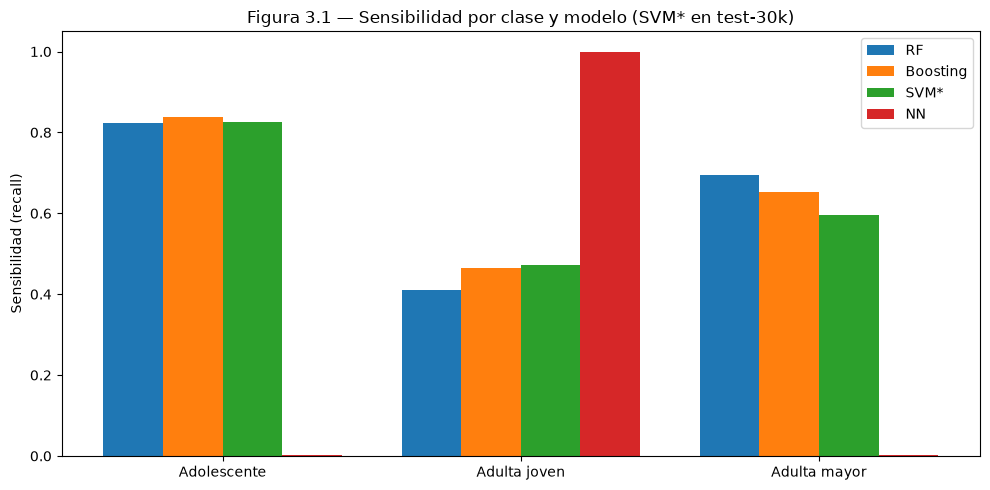

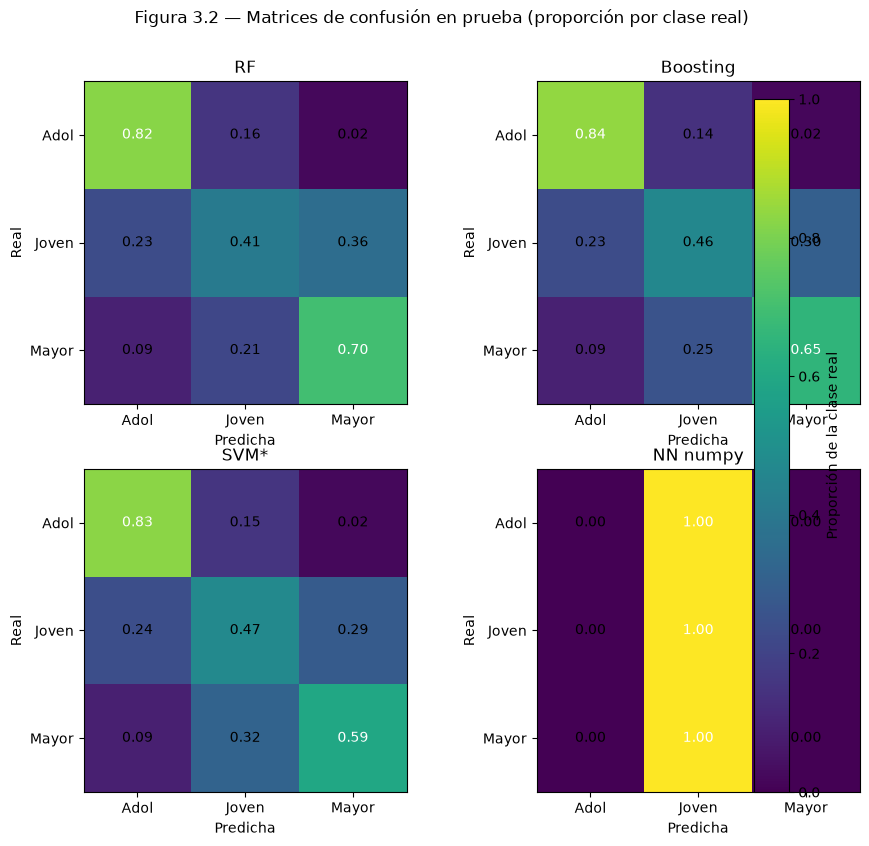

In [22]:
x = np.arange(3)
w = 0.2
plt.figure(figsize=(10, 5))
for i, (nombre, m) in enumerate([('RF', m_rf), ('Boosting', m_gb), ('SVM*', m_svm), ('NN', m_nn)]):
    plt.bar(x + (i - 1.5) * w, m['sens'], width=w, label=nombre)
plt.xticks(x, ['Adolescente', 'Adulta joven', 'Adulta mayor'])
plt.ylabel('Sensibilidad (recall)')
plt.ylim(0, 1.05)
plt.title('Figura 3.1 — Sensibilidad por clase y modelo (SVM* en test-30k)')
plt.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(2, 2, figsize=(11, 9))
for a, (nombre, m) in zip(ax.flat, [('RF', m_rf), ('Boosting', m_gb), ('SVM*', m_svm), ('NN numpy', m_nn)]):
    cmn = m['cm'].astype(float) / m['cm'].sum(axis=1, keepdims=True)
    im = a.imshow(cmn, vmin=0, vmax=1)
    a.set_xticks(range(3), ['Adol', 'Joven', 'Mayor'])
    a.set_yticks(range(3), ['Adol', 'Joven', 'Mayor'])
    a.set_xlabel('Predicha'); a.set_ylabel('Real')
    a.set_title(nombre)
    for r in range(3):
        for c_ in range(3):
            a.text(c_, r, f'{cmn[r, c_]:.2f}', ha='center', va='center',
                   color='white' if cmn[r, c_] > 0.5 else 'black')
fig.colorbar(im, ax=ax, label='Proporción de la clase real')
fig.suptitle('Figura 3.2 — Matrices de confusión en prueba (proporción por clase real)')
fig.subplots_adjust(top=0.90, right=0.88)
plt.show()

**Interpretación de las Tablas 3.1–3.2 y Figuras 3.1–3.2.** Los tres modelos que dan peso extra a los grupos pequeños terminan muy parejos: Boosting (0.652), RF (0.643) y SVM (0.631) en balanced accuracy. Las diferencias entre ellos son chicas (±0.02), pero los tres dejan atrás al árbol único (0.518) y al discriminante (0.370). El costo se ve en el acierto total, que baja de ~0.73 a 0.50–0.54: al obligar al modelo a atender a todos, la adulta joven (el grupo grande) se acierta menos (0.41–0.47), mientras la adolescente sube a 0.82–0.84 (antes 0.60 y 0.04) y la adulta mayor a 0.59–0.70 (antes 0.06). La Figura 3.1 muestra ese intercambio grupo por grupo y la Figura 3.2 lo confirma: en los tres modelos la joven se reparte entre las dos minoritarias, que ahora sí aparecen en la diagonal. La red es el caso contrario: acierta 0.729 porque predice casi siempre adulta joven (sensibilidad 0.999 ahí, ~0 en el resto) y su balanced de 0.334 equivale a adivinar. Al no compensar el desbalance, el entrenamiento premia a la mayoría e ignora al resto. El SVM rinde casi igual que el bosque entrenando con solo 4% de los datos, aunque el 89% de esa muestra terminó como vector de soporte: la frontera entre grupos es muy enredada.

## 4. Análisis crítico y conclusiones

**Complejidad frente a ganancia.** Más complejidad sí ayudó, pero solo con compensación del desbalance: RF y Boosting entrenan en menos de un minuto con todos los datos y suben +0.12 sobre el árbol único. El SVM, el más caro (0.6 min entrenando más 0.9 min para predecir 30 mil casos), no supera a Boosting. La red, barata de entrenar, no aporta nada sin atender a los grupos chicos.

**Sobreajuste.** Boosting termina con la misma pérdida en train y validación; RF se protege exigiendo 1000 madres por hoja; la red se detuvo sola en la vuelta 20. El riesgo real es el SVM: con 89% de vectores de soporte más memoriza que generaliza, y sus controles se fijaron por criterio sin validación cruzada.

**Interpretabilidad.** El árbol único se lee como reglas; el arbolito de la Figura 2.5 resume al bosque en 3 preguntas; RF conserva algo vía importancias; Boosting, SVM y la red son cajas negras de utilidad decreciente para explicar decisiones.

**Cuándo preferir cada uno.** Para detectar embarazo adolescente, donde lo grave es dejar escapar casos, Boosting o RF (detectan 82–84 de cada 100 adolescentes) aceptando falsas alarmas (de cada 10 señaladas, unas 4 sí lo son). Para una regla explicable en campo, el árbol único o el arbolito. El SVM solo con cómputo de sobra y validación de sus controles. La red, así como está, no se recomienda.

**Límites.** Las variables que más pesan (número de parto, estado civil) describen el parto, no permiten prevenirlo antes. La adulta mayor sigue costando (se detecta 60–70 de cada 100) y el modelo sirve para priorizar vigilancia, no para diagnóstico individual.

No hay un ganador absoluto: Boosting rinde más, RF le sigue de cerca con lógica más estable, el SVM empata a mayor costo y la red colapsa. Con un reparto de 73/14/13, compensar a los grupos chicos pesa más que la sofisticación del algoritmo.

Doy mi palabra que he realizado esta actividad con integridad academica

**Referencias**

- Organización Mundial de la Salud. (2024). *Salud del adolescente*. https://www.who.int/es/health-topics/adolescent-health
- Instituto Nacional de Estadística y Geografía. (2024). *Estadística de Nacimientos 2024 (nacim24)*. https://www.inegi.org.mx

*Nota: se utilizó inteligencia artificial generativa como apoyo para la redacción de código y la edición del texto.